## Investigating Differences in Temperature and Precipitation between CMIP5 and CMIP6

In this exercise, you will be working with global mean near surface air temperature (tas) and total precipitation (pr) data from the 1$\%$ yr$^{-1}$ idealized emission scenarios in the CMIP5 and CMIP6 archives. The global mean data for CMIP5 and CMIP6 will be provided to you in a netCDF format, to save time. In the end, you will be creating a 4-panel plot, comparing the timeseries of the CMIP5 and CMIP6 global mean temperature, and precipitation, as well as creating a couple of boxplots to compare the ensemble mean, and spread in Year 140.

### Required Files

+ CMIP6_1pctCO2_pr_tas.nc
+ CMIP5_1pctCO2_pr_tas.nc

### Load CMIP5 and CMIP6 global mean data, and store in a Pandas DataFrame

The first step will be to grab the global mean tas and pr data for both CMIP5 and CMIP6 (which has already been downloaded and pre-processed). We are going to store the global mean timeseries for each model in the CMIP5 and CMIP6 archives in a Pandas Dataframe. We will also subset the data to only include the first 140 years (common to all models).

In [1]:
### Load the necessary packages ###
from matplotlib import pyplot as plt
import xarray as xr
import numpy as np
import pandas as pd
import dask

### Load CMIP6 data from nc file ###
CMIP6_fil = 'CMIP6_1pctCO2_pr_tas.nc'
CMIP6_ds = xr.open_dataset(CMIP6_fil)

### Load CMIP5 data from nc file ###
CMIP5_fil = 'CMIP5_1pctCO2_pr_tas.nc'
CMIP5_ds = xr.open_dataset(CMIP5_fil)

### Convert CMIP5 dataset into Pandas Dataframe ###
df_CMIP5 = CMIP5_ds.sel(year=slice(0,139)).to_dataframe().reset_index() # select common time period across all models
df_CMIP5['CMIP Version'] = 'CMIP5' # add new column to denote which CMIP archive the data is from

### Convert CMIP6 dataset into Pandas Dataframe ###
df_CMIP6 = CMIP6_ds.sel(year=slice(0,139)).to_dataframe().reset_index()
df_CMIP6['CMIP Version'] = 'CMIP6' # add new column to denote which CMIP archive the data is from

### Subset CMIP6 data and change columns to match CMIP5 dataframe ##
df_CMIP6_subset = df_CMIP6[['source_id','year','pr','tas','CMIP Version']] # we only want the model, year, CMIP version and the timeseries for tas and pr
df_CMIP6_subset = df_CMIP6_subset.rename(columns={'source_id':'model'}) #rename 'source_id' column to 'model'
df_CMIP6_subset = df_CMIP6_subset[~df_CMIP6_subset['model'].isin(['CIESM','MCM-UA-1-0'])] #remove CIESM and MCM-UA-1-0 models

### Concatenate CMIP5 and CMIP6 datasets together ###
df_all = pd.concat([df_CMIP5,df_CMIP6_subset])

### Investigate the Dataframe

Now that we've created the combined dataframe, let's take a look at its structure. Note that the units of 'tas' are in degrees Kelvin, and 'pr' is in kg m-2 s-1 (stored as a precipitation flux):

In [2]:
print(df_all)

          model   year         tas        pr CMIP Version
0     ACCESS1-0    0.0  286.767182  0.000036        CMIP5
1     ACCESS1-0    1.0  286.918590  0.000036        CMIP5
2     ACCESS1-0    2.0  286.861676  0.000036        CMIP5
3     ACCESS1-0    3.0  286.897332  0.000036        CMIP5
4     ACCESS1-0    4.0  287.016942  0.000036        CMIP5
...         ...    ...         ...       ...          ...
6435    TaiESM1  135.0  292.767076  0.000039        CMIP6
6436    TaiESM1  136.0  292.818815  0.000039        CMIP6
6437    TaiESM1  137.0  293.008870  0.000039        CMIP6
6438    TaiESM1  138.0  292.965127  0.000039        CMIP6
6439    TaiESM1  139.0  293.197517  0.000039        CMIP6

[9380 rows x 5 columns]


### Calculate Decadal Means ###

In order to prepare the data for plotting, we are going to calculate the decadal mean pr and tas, and store this in a decadal_means dataframe. We will also convert precipitation from a flux (in kg m-2 s-1) to mm/year. Let's take a look at the resulting decadal mean dataframe:

In [3]:
### Convert precipitation flux to mm year-1 ###
df_all['precip mm yr-1'] = df_all['pr']*86400*365

# ### Create Decade Column ###
df_all['decade'] = df_all.year.floordiv(10).mul(10) #determine decade that each year falls in

### Calculate decadal mean tas and pr
df_decadal_means = df_all.groupby(['model','CMIP Version','decade']).mean().reset_index().dropna() #groupby model and decade and calculate mean (we also group by CMIP version to set this as an index)
df_last10years = df_decadal_means[df_decadal_means['decade'] == 130] #grab last decadal mean for boxplot later

print(df_decadal_means)

          model CMIP Version  decade   year         tas        pr  \
0    ACCESS-CM2        CMIP6     0.0    4.5  287.051778  0.000036   
1    ACCESS-CM2        CMIP6    10.0   14.5  287.292466  0.000036   
2    ACCESS-CM2        CMIP6    20.0   24.5  287.561578  0.000037   
3    ACCESS-CM2        CMIP6    30.0   34.5  287.868845  0.000037   
4    ACCESS-CM2        CMIP6    40.0   44.5  288.170034  0.000037   
..          ...          ...     ...    ...         ...       ...   
933      inmcm4        CMIP5    90.0   94.5  288.098933  0.000037   
934      inmcm4        CMIP5   100.0  104.5  288.304546  0.000037   
935      inmcm4        CMIP5   110.0  114.5  288.574474  0.000037   
936      inmcm4        CMIP5   120.0  124.5  288.757447  0.000037   
937      inmcm4        CMIP5   130.0  134.5  288.994184  0.000037   

     precip mm yr-1  
0       1145.805627  
1       1149.109854  
2       1153.607711  
3       1160.040241  
4       1167.171354  
..              ...  
933     1165.9053

### Create Summary Figures

At this point it is time to investigate how the ensemble mean and spread in CMIP5 and CMIP6 temperature and precipitation differ. You will be creating a 4-panel figure based on the decadal means. The top 2 panels will show the decadal mean timeseries for tas, and pr, while the bottom 2 panels will consist of boxplots comparing the distribution of the the decadal, global mean tas and pr, over the last decade of the simulation, across all models in the CMIP5 and CMIP6 datasets:

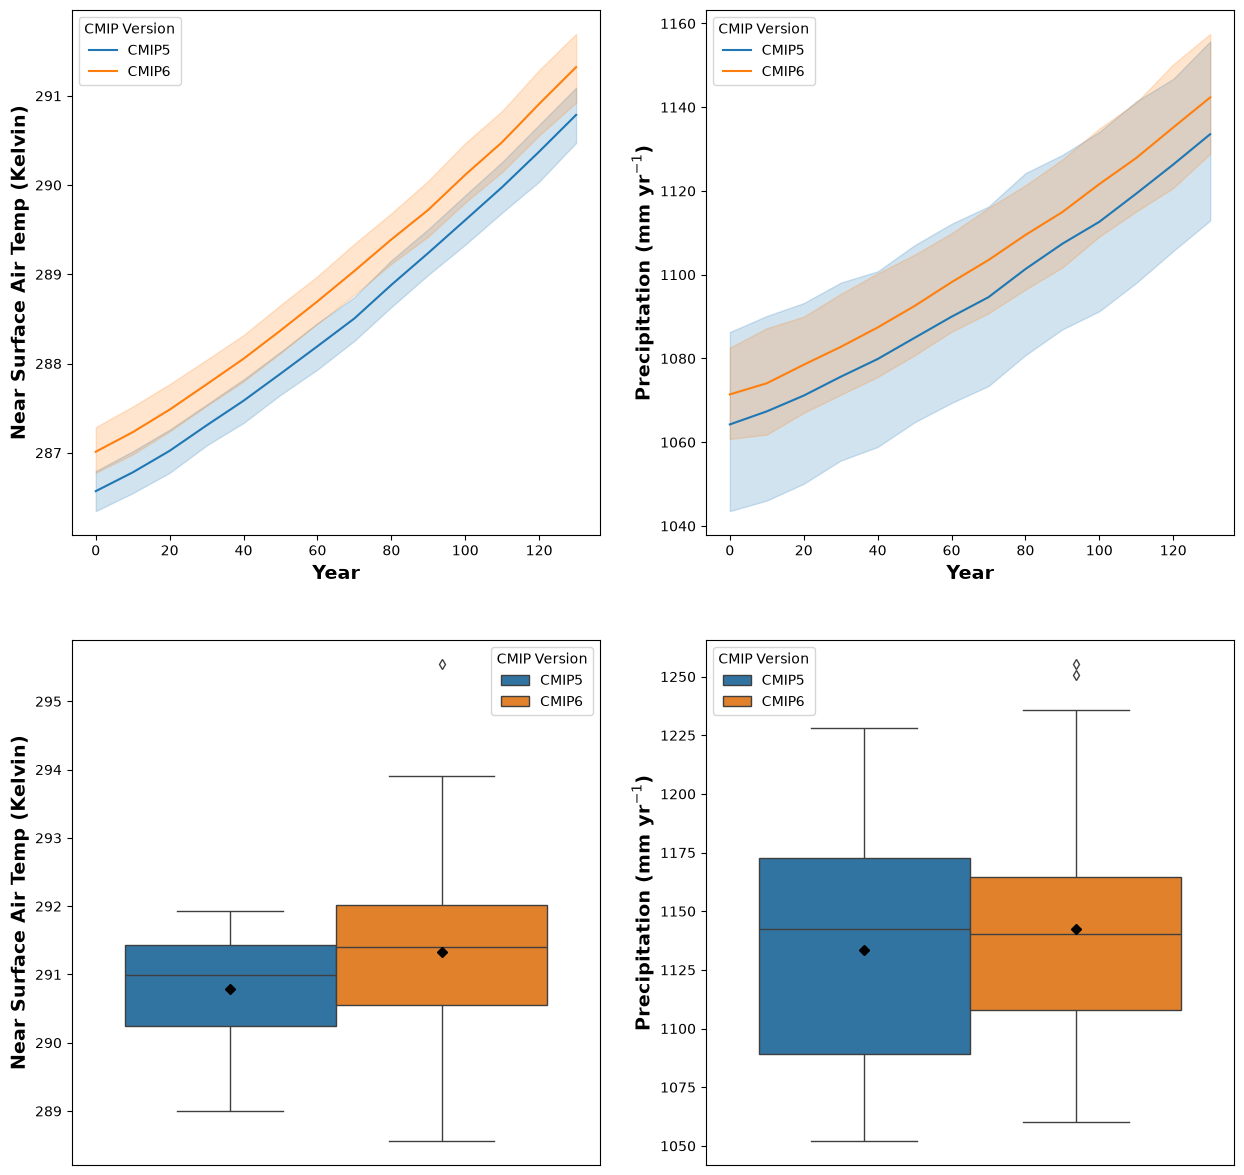

In [4]:
### Load Plotting Tools (Matplotlib and Seaborn) ###
from matplotlib import pyplot as plt
import seaborn as sns

### Create Figures ###
fig,axs = plt.subplots(nrows=2,ncols=2,figsize=(15,15)) #initialize a 4 panel figure

mean_style={"marker":"D", "markerfacecolor":"black", "markeredgecolor":"black", "markersize":"5"} #customize the display of the ensemble mean in the boxplot
flierprops = dict(marker='d', markersize=5) #customize the display of the ensemble mean in the boxplot

## tas timeseries ##
ax1 = plt.subplot(221)
sns.lineplot(data=df_decadal_means,
            x="decade", y="tas", hue='CMIP Version',hue_order=['CMIP5','CMIP6'],
            errorbar=('ci', 95),ax=ax1) #use the 95% confidence interval 
ax1.set_ylabel('Near Surface Air Temp (Kelvin)',fontsize=14,fontweight='bold')
ax1.set_xlabel('Year',fontsize=14,fontweight='bold')

## pr timeseries ##
ax2 = plt.subplot(222)
sns.lineplot(data=df_decadal_means,
            x="decade", y="precip mm yr-1", hue='CMIP Version',hue_order=['CMIP5','CMIP6'],
            errorbar=('ci', 95),ax=ax2) #use the 95% confidence interval
ax2.set_ylabel('Precipitation (mm yr$^{-1}$)',fontsize=14,fontweight='bold')
ax2.set_xlabel('Year',fontsize=14,fontweight='bold')

### tas boxplot ###
### Look at 5-10 year mean ###

ax3 = plt.subplot(223)
sns.boxplot(data=df_last10years,x="decade", y="tas", hue='CMIP Version',hue_order=['CMIP5','CMIP6'],showmeans=True,meanprops=mean_style,flierprops=flierprops,ax=ax3)
ax3.set_ylabel('Near Surface Air Temp (Kelvin)',fontsize=14,fontweight='bold')
ax3.set_xlabel('') #no x-label needed for boxplots
ax3.set_xticks([]) #remove x-ticks

### pr boxplot ###
ax4 = plt.subplot(224)
sns.boxplot(df_last10years,x="decade", y="precip mm yr-1", hue='CMIP Version',hue_order=['CMIP5','CMIP6'],showmeans=True,meanprops=mean_style,flierprops=flierprops,ax=ax4)
ax4.set_ylabel('Precipitation (mm yr$^{-1}$)',fontsize=14,fontweight='bold')
ax4.set_xlabel('') #no x-label needed for boxplots
ax4.set_xticks([]) #remove x-ticks

plt.show()

### Reflection Questions

In Module 4, you analyzed the global mean near surface air temperature (tas) and total precipitation (pr) data from the 1$\%$ yr$^{-1}$ idealized emission scenarios in the CMIP5 and CMIP6 archives. We leave you with a couple of reflection questions:

1) How do the ensemble mean temperature and precipitation differ between CMIP5 and CMIP6? What could account for their differences? (hint: look back at Module 3)
2) Comment on the differences in ensemble spread between CMIP5 and CMIP5 temperature and precipitation in Year 140. How does this relate to what you found in Module 3? 